# Project 4 dataset: regression analysis

500 observations of four continuous predictors (`x1`-`x4`) and a continuous response (`y`).
Nothing is known in advance about how `y` was generated, so the analysis works outward from
the data: describe the marginals, fit the simplest reasonable model, read the residuals for
what that model got wrong, and add structure only where a test supports it.

Logic lives in three adjacent modules (`data_tools.py`, `modeling.py`, `analysis_plots.py`);
this notebook is the narrative. Figures are written to `figures/` as editable SVG plus PNG.

**Conclusion reached below.** The additive linear model that the column names invite is wrong
in three separate ways, and each one is invisible in the marginal correlations:

1. `x1` and `x2` act only through their **product**; neither has a main effect, and each has a
   marginal correlation with `y` of essentially zero.
2. `x3` enters as a **symmetric quadratic**, so its linear coefficient and its marginal
   correlation are both near zero while the term itself is the largest in the model.
3. The error **standard deviation grows with `x4`**, which inflates the apparent tail weight of
   the residuals and makes ordinary standard errors unreliable.

Pairwise collinearity, by contrast, is absent here (all VIFs are 1.0) despite being the hazard
one usually looks for first.

In [1]:
import warnings

import numpy as np
import pandas as pd
from scipy import stats

import analysis_plots as ap
import data_tools as dt
import modeling as md

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 120)
ap.set_style()

df = dt.load_dataset("project_4_dataset.csv")
df.shape

(500, 5)

## 1. Marginal distributions

Before any test, look at the shapes. Linear regression makes no assumption about the marginal
distribution of a predictor or of the response, so nothing here is yet a violation; the point
is to know what the columns are.

In [2]:
summary = dt.summarise_distributions(df)
summary.round(3)

,n,mean,sd,min,median,max,skew,excess_kurtosis,shapiro_p
variable,,,,,,,,,
x1,500,0.032,1.048,-3.747,0.063,3.151,0.019,0.195,0.609
x2,500,0.011,1.015,-2.891,0.001,3.236,-0.105,0.029,0.405
x3,500,-0.101,0.963,-3.059,-0.082,3.334,-0.042,0.276,0.183
x4,500,1.469,0.861,0.005,1.410,2.998,0.086,-1.199,0.000
y,500,2.011,5.736,-24.253,0.922,32.078,1.155,4.711,0.000


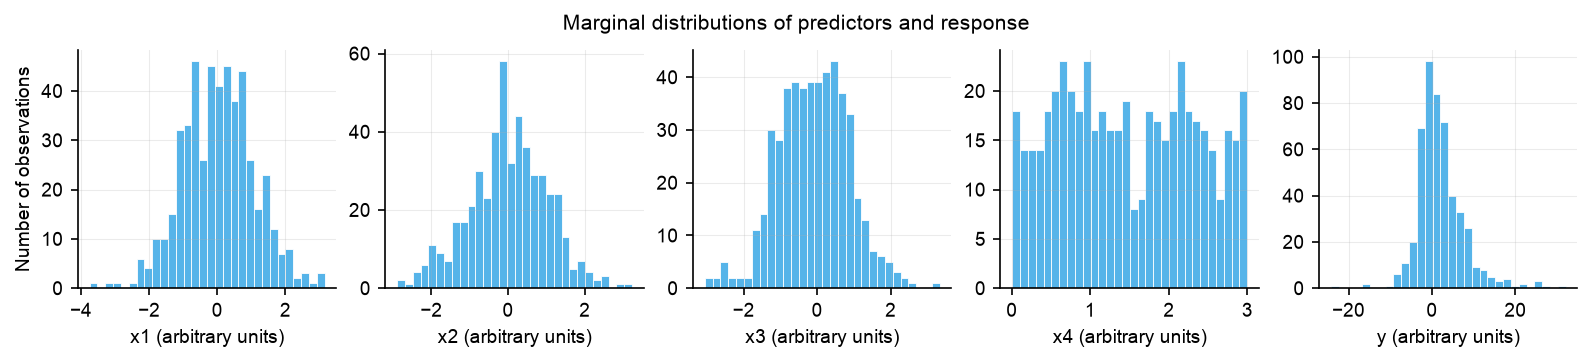

In [3]:
fig = ap.plot_distributions(df, dt.PREDICTORS + [dt.RESPONSE])

`x1`, `x2` and `x3` are near-standard normal. `x4` is flat between 0 and 3, i.e. uniform, not
normal, which is unremarkable for a designed or sampled covariate. `y` is right-skewed with
heavy tails (skew 1.16, excess kurtosis 4.7). That skew is a property of the *marginal*
distribution of `y`; whether the *errors* are skewed is a separate question that only the
residuals can answer, and transforming `y` at this stage would be premature.

## 2. Marginal associations, and why they are not a screening tool

Pearson and Spearman correlations of each predictor with `y`. Both are shown because a
predictor entering through a symmetric nonlinearity or through a product with another
predictor has a near-zero correlation under either measure - so a weak marginal correlation is
not grounds for dropping a variable.

In [4]:
corr = dt.correlation_table(df)
corr.round(4)

,pearson_r,pearson_p,spearman_rho,spearman_p
predictor,,,,
x1,0.0184,0.6814,0.0237,0.5969
x2,0.0801,0.0737,0.0420,0.3487
x3,-0.0963,0.0314,-0.0903,0.0436
x4,0.2548,0.0000,0.2895,0.0000


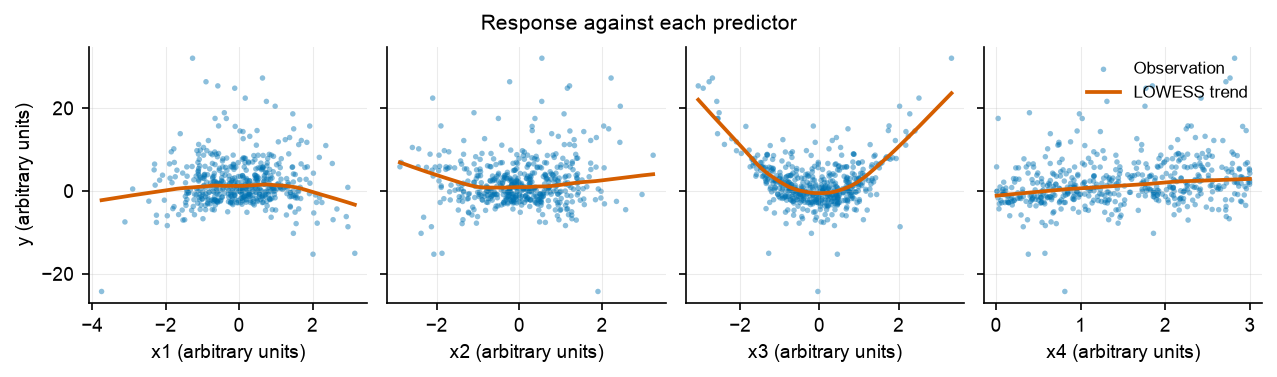

In [5]:
fig = ap.plot_response_vs_predictors(df, dt.PREDICTORS)

Only `x4` has an appreciable marginal correlation (r = 0.25). `x1` and `x2` sit at
r = 0.02 and 0.08; `x3` at -0.10. The LOWESS curves in the figure already contradict that
reading for `x3`, whose trend is U-shaped: the rise on the left and the rise on the right
cancel in the correlation coefficient. The `x4` panel also shows the scatter fanning out to
the right, which is a variance effect rather than a mean effect.

## 3. Baseline: the additive linear model

Fit `y ~ x1 + x2 + x3 + x4`, then check it rather than report it.

In [6]:
additive = md.fit_ols(df, md.ADDITIVE_FORMULA)
md.coefficient_table(additive).round(4)

,estimate,std_error,t,p,ci_low,ci_high
Intercept,-0.6321,0.4904,-1.2888,0.1981,-1.5957,0.3315
x1,0.1145,0.2353,0.4864,0.6269,-0.3479,0.5768
x2,0.4891,0.2433,2.0100,0.0450,0.0110,0.9671
x3,-0.6932,0.2568,-2.6992,0.0072,-1.1978,-0.1886
x4,1.7456,0.2870,6.0830,0.0000,1.1818,2.3094


In [7]:
print(f"R-squared            {additive.rsquared:.3f}")
print(f"Ramsey RESET p       {md.reset_test(additive):.4g}   (unmodelled nonlinearity in the mean)")
print(f"Breusch-Pagan p      {md.breusch_pagan_p(additive):.4g}   (non-constant error variance)")
print(f"Shapiro-Wilk p       {stats.shapiro(additive.resid).pvalue:.3g}   (residual normality)")
md.vif_table(df, dt.PREDICTORS).round(3)

R-squared            0.085
Ramsey RESET p       0.01195   (unmodelled nonlinearity in the mean)
Breusch-Pagan p      0.03902   (non-constant error variance)
Shapiro-Wilk p       2.23e-16   (residual normality)


,vif
predictor,
const,1.000
x1,1.000
x2,1.003
x3,1.006
x4,1.004


The model explains 8.5% of the variance. All four variance inflation factors are 1.0, so
**collinearity is not a problem in this dataset** - the predictors are mutually orthogonal and
every coefficient is cleanly identified. The RESET test (p = 0.012) and the Breusch-Pagan test
(p = 0.039) both reject, and the residuals fail Shapiro-Wilk decisively (p = 2.2e-16, skew
1.08, excess kurtosis 4.46). Taking the coefficient
table at face value here would be the central error available in these data.

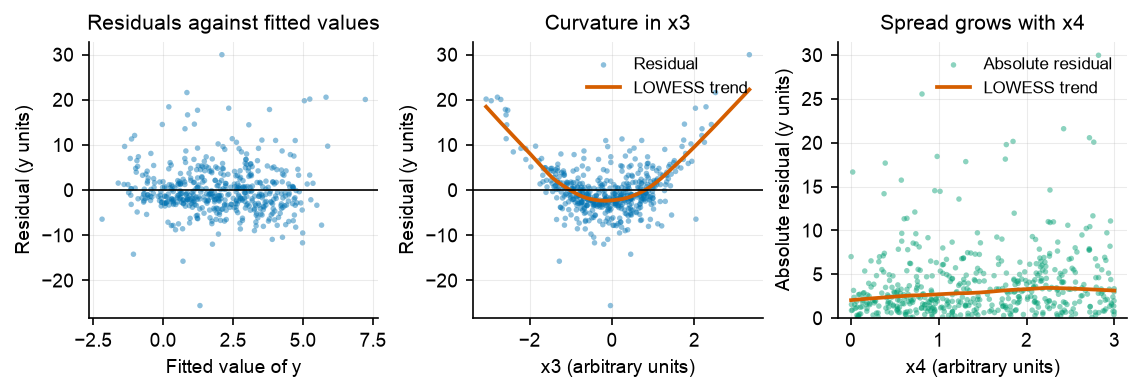

In [8]:
fig = ap.plot_additive_diagnostics(additive, df)

The middle panel shows the residual curvature in `x3`: strongly positive at both ends,
negative in the middle. The right panel shows the absolute residuals climbing steadily with
`x4`. These are two different defects and they need two different fixes.

## 4. What the residuals ask for: curvature and interaction

Two targeted scans. For each predictor, an F-test for adding a quadratic term; and for each
of the six pairs, an F-test for adding a product term. The pairwise scan is six tests, so the
p-values are adjusted by Benjamini-Hochberg before being read as a set.

In [9]:
curv = md.residual_diagnostics(additive, df, dt.PREDICTORS)
curv["curvature_p_fdr"] = dt.fdr_adjust(curv["curvature_p"])
curv.round(4)

,curvature_p,abs_resid_rho,abs_resid_p,curvature_p_fdr
predictor,,,,
x1,0.0000,-0.0631,0.1591,0.0000
x2,0.0040,0.0896,0.0452,0.0054
x3,0.0000,0.0518,0.2474,0.0000
x4,0.8819,0.1542,0.0005,0.8819


In [10]:
inter = md.interaction_scan(df, md.ADDITIVE_FORMULA, dt.PREDICTORS)
inter["p_fdr"] = dt.fdr_adjust(inter["p"])
inter.sort_values("p").round(5)

,delta_r2,p,p_fdr
term,,,
x1:x2,0.31831,0.00000,0.00000
x3:x4,0.00979,0.02118,0.04411
x1:x3,0.00966,0.02206,0.04411
x2:x3,0.00291,0.20989,0.31483
x2:x4,0.00095,0.47407,0.47861
x1:x4,0.00093,0.47861,0.47861


The `x1:x2` product is overwhelming: it alone adds 0.32 to R-squared. The quadratic scan flags
`x3` (the real curvature) but also `x1` and `x2` - those are artefacts, because an omitted
product term projects onto the squared terms of its own factors. The weaker interaction hits
(`x1:x3`, `x3:x4`, both FDR ~ 0.04) are likewise an artefact of the missing `x3` quadratic.
This is why the scans are re-run after the mean model is corrected rather than read once.

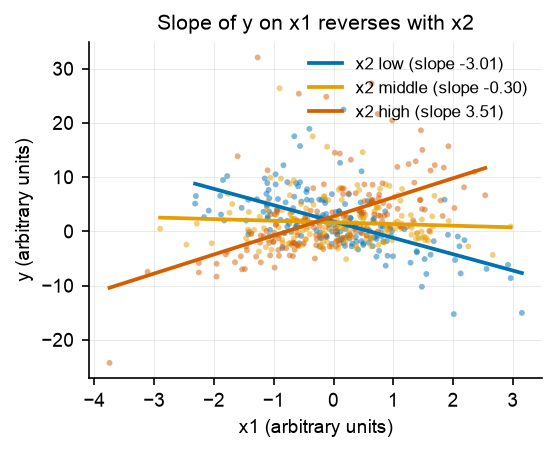

In [11]:
fig = ap.plot_interaction(df)

Splitting the sample by terciles of `x2` makes the interaction concrete: the slope of `y` on
`x1` is strongly negative in the low-`x2` third and strongly positive in the high-`x2` third.
Averaged over `x2` the two cancel, which is exactly why the marginal correlation of `x1` with
`y` was 0.02.

## 5. Structured mean model

Add the `x3` quadratic and the `x1:x2` product. Main effects for `x1`, `x2` and `x3` are
retained whatever their p-values, because dropping a main effect while keeping its product or
square makes the remaining coefficients depend on the arbitrary origin of the predictor.

In [12]:
structured = md.fit_ols(df, md.STRUCTURED_FORMULA)
md.coefficient_table(structured).round(4)

,estimate,std_error,t,p,ci_low,ci_high
Intercept,-3.0807,0.1621,-18.9990,0.0000,-3.3993,-2.7621
x1,0.0943,0.0749,1.2597,0.2084,-0.0528,0.2414
x2,0.0260,0.0777,0.3341,0.7385,-0.1268,0.1787
x1:x2,3.0413,0.0699,43.5289,0.0000,2.9040,3.1786
x3,0.0069,0.0829,0.0835,0.9335,-0.1560,0.1698
I(x3 ** 2),2.9326,0.0565,51.9341,0.0000,2.8217,3.0436
x4,1.5913,0.0914,17.4015,0.0000,1.4116,1.7709


In [13]:
print(f"R-squared        {structured.rsquared:.3f}  (additive model: {additive.rsquared:.3f})")
print(f"Ramsey RESET p   {md.reset_test(structured):.3f}   (mean structure now adequate)")
print(f"Breusch-Pagan p  {md.breusch_pagan_p(structured):.3g}   (variance problem remains)")

R-squared        0.908  (additive model: 0.085)
Ramsey RESET p   0.237   (mean structure now adequate)
Breusch-Pagan p  3.87e-14   (variance problem remains)


In [14]:
rescan = md.interaction_scan(df, "y ~ x1 + x2 + x3 + I(x3**2) + x4", dt.PREDICTORS)
rescan["p_fdr"] = dt.fdr_adjust(rescan["p"])
rescan.sort_values("p").round(5)

,delta_r2,p,p_fdr
term,,,
x1:x2,0.35425,0.00000,0.00000
x1:x4,0.00456,0.02447,0.07342
x2:x4,0.00106,0.27938,0.55876
x2:x3,0.00024,0.60658,0.87102
x1:x3,0.00005,0.80954,0.87102
x3:x4,0.00002,0.87102,0.87102


R-squared rises from 0.085 to 0.908 and RESET no longer rejects (p = 0.24), so the mean
function is adequate. With the quadratic in place the spurious interactions disappear: apart
from `x1:x2`, no pair survives FDR adjustment (`x1:x4` is the closest at FDR = 0.07). But
Breusch-Pagan still rejects at p ~ 4e-14 - the variance defect is untouched, as it should be,
since it is not a mean-structure problem.

## 6. The variance function

Regress the log squared residuals on `x4`. A linear fit on that scale corresponds to a
multiplicative variance model, sigma^2(x4) = exp(a + b * x4), which keeps the fitted variance
positive everywhere. The intercept is corrected by 1.2704 = -E[log chi^2_1] before being read
as a log variance, since log of a squared residual is biased low; the correction is a constant
and so leaves the weighted estimates unchanged, but it puts the standardised residuals on a
unit-variance scale.

In [15]:
aux = md.variance_model(structured, df, "x4")
print(md.coefficient_table(aux).round(4).to_string())
weights = md.variance_weights(aux)
a = aux.params["Intercept"] + md.LOG_CHI2_BIAS   # bias correction, see modeling.LOG_CHI2_BIAS
b = aux.params["x4"]
print(f"\nfitted error SD:  exp({0.5 * a:+.3f} {0.5 * b:+.3f} * x4)")
print(f"implied SD at x4 = 0.0:  {np.exp(0.5 * a):.2f}")
print(f"implied SD at x4 = 3.0:  {np.exp(0.5 * (a + 3 * b)):.2f}")

           estimate  std_error        t    p  ci_low  ci_high
Intercept   -2.3536     0.2039 -11.5410  0.0 -2.7543  -1.9529
x4           1.1924     0.1198   9.9546  0.0  0.9571   1.4278

fitted error SD:  exp(-0.542 +0.596 * x4)
implied SD at x4 = 0.0:  0.58
implied SD at x4 = 3.0:  3.48


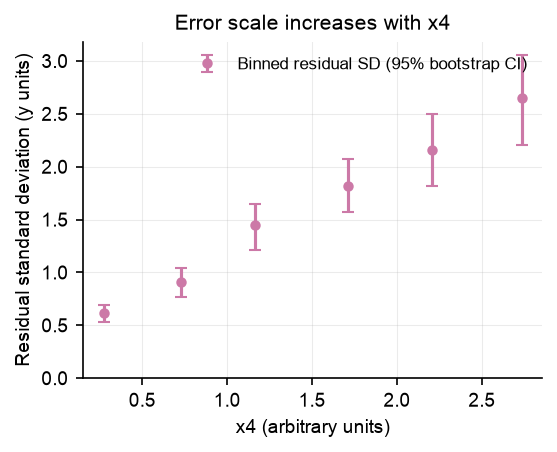

In [16]:
fig = ap.plot_variance_function(df, np.asarray(structured.resid))

Two descriptions of the same spread, which should not be conflated. The *empirical* standard
deviation within sixths of `x4` (the figure) runs 0.62 in the lowest sixth to 2.65 in the
highest - a 4.3-fold change, so an observation at high `x4` carries roughly a eighteenth of the
information of one at low `x4`. The *fitted* curve (printed above) runs 0.58 at `x4` = 0 to
3.48 at `x4` = 3; it is steeper because each bin averages over a range of `x4`, and at the top
bin's mean of `x4` = 2.73 the fitted value is 2.97 against the binned 2.65. Ordinary least
squares weights all of these observations equally.

## 7. Weighted fit and final inference

Refit by weighted least squares with weights 1 / estimated variance.

In [17]:
final = md.fit_wls(df, md.STRUCTURED_FORMULA, weights)
std_resid = md.standardised_residuals(final, weights)
md.coefficient_table(final).round(4)

,estimate,std_error,t,p,ci_low,ci_high
Intercept,-3.0017,0.0847,-35.4299,0.0000,-3.1682,-2.8352
x1,0.0333,0.0474,0.7015,0.4833,-0.0599,0.1264
x2,0.0267,0.0539,0.4948,0.6210,-0.0792,0.1326
x1:x2,2.9991,0.0432,69.4134,0.0000,2.9142,3.0840
x3,0.0606,0.0576,1.0513,0.2936,-0.0526,0.1738
I(x3 ** 2),2.9726,0.0413,72.0499,0.0000,2.8916,3.0537
x4,1.4951,0.0798,18.7434,0.0000,1.3384,1.6518


In [18]:
print(f"Shapiro-Wilk p (standardised residuals)  {stats.shapiro(std_resid).pvalue:.3f}")
print(f"Breusch-Pagan p (standardised residuals) {md.breusch_pagan_p(final, std_resid):.3f}")
print(f"skew {stats.skew(std_resid):+.3f}   excess kurtosis {stats.kurtosis(std_resid):+.3f}")

Shapiro-Wilk p (standardised residuals)  0.949
Breusch-Pagan p (standardised residuals) 0.579
skew -0.094   excess kurtosis +0.010


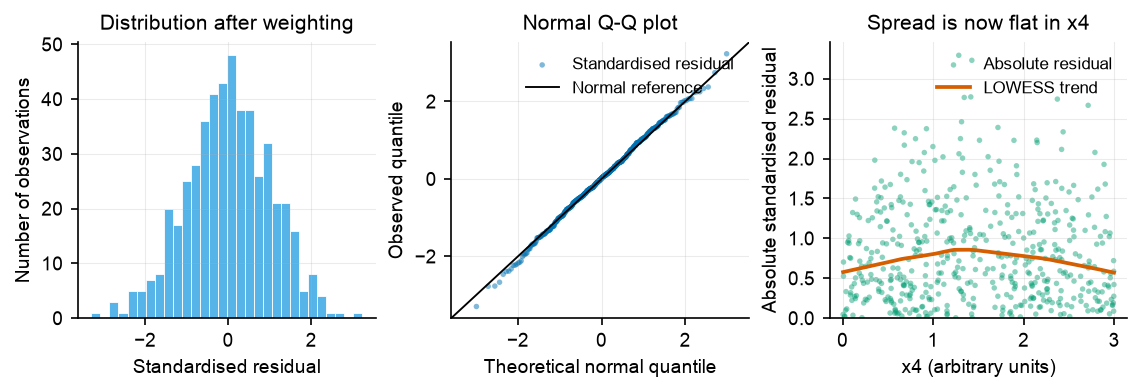

In [19]:
fig = ap.plot_final_diagnostics(std_resid, df)

Once the variance function is accounted for, the standardised residuals are normal
(Shapiro-Wilk p = 0.95, skew -0.09, excess kurtosis 0.01) and their spread is flat in `x4`.
The unweighted residuals of the same mean model failed that test at p = 5.4e-7 (skew -0.16,
excess kurtosis 1.84), and those of the additive model at p = 2.2e-16 (skew 1.08, excess
kurtosis 4.46). The apparent non-normality was therefore **induced by the heteroscedasticity**, not by a heavy-tailed error family: it is a mixture of normals with
different scales. Transforming `y` or switching to a robust loss would have treated the
symptom.

Because that conclusion rests on a diagnostic rather than an assumption, the key coefficients
are confirmed two further ways that do not require normal errors: a Freedman-Lane permutation
test for each term, and a pairs bootstrap that re-estimates the variance model inside every
resample.

In [20]:
perm = pd.DataFrame(
    md.permutation_test_term(df, md.STRUCTURED_FORMULA, term, weights=weights, n_perm=1000)
    for term in ["x1:x2", "I(x3**2)", "x4", "x1", "x2", "x3"]
).set_index("term")
perm["p_fdr"] = dt.fdr_adjust(perm["p_permutation"])
perm.round(4)

,t_observed,p_permutation,n_perm,p_fdr
term,,,,
x1:x2,69.4134,0.0010,1000,0.0020
I(x3**2),72.0499,0.0010,1000,0.0020
x4,18.7434,0.0010,1000,0.0020
x1,0.7015,0.6374,1000,0.7073
x2,0.4948,0.7073,1000,0.7073
x3,1.0513,0.3926,1000,0.5889


In [21]:
boot = md.bootstrap_coefficients(df, md.STRUCTURED_FORMULA, "x4", n_boot=1000)
pd.concat([md.coefficient_table(final)[["estimate", "std_error", "ci_low", "ci_high"]], boot], axis=1).round(3)

,estimate,std_error,ci_low,ci_high,boot_sd,boot_ci_low,boot_ci_high
Intercept,-3.002,0.085,-3.168,-2.835,0.075,-3.143,-2.851
x1,0.033,0.047,-0.060,0.126,0.045,-0.057,0.118
x2,0.027,0.054,-0.079,0.133,0.058,-0.079,0.148
x1:x2,2.999,0.043,2.914,3.084,0.044,2.909,3.078
x3,0.061,0.058,-0.053,0.174,0.054,-0.047,0.162
I(x3 ** 2),2.973,0.041,2.892,3.054,0.037,2.893,3.037
x4,1.495,0.080,1.338,1.652,0.075,1.349,1.649


The permutation p-values agree with the weighted-least-squares p-values on every term, and the
bootstrap standard errors are close to the model-based ones, so the inference is not resting on
the variance model being exactly right.

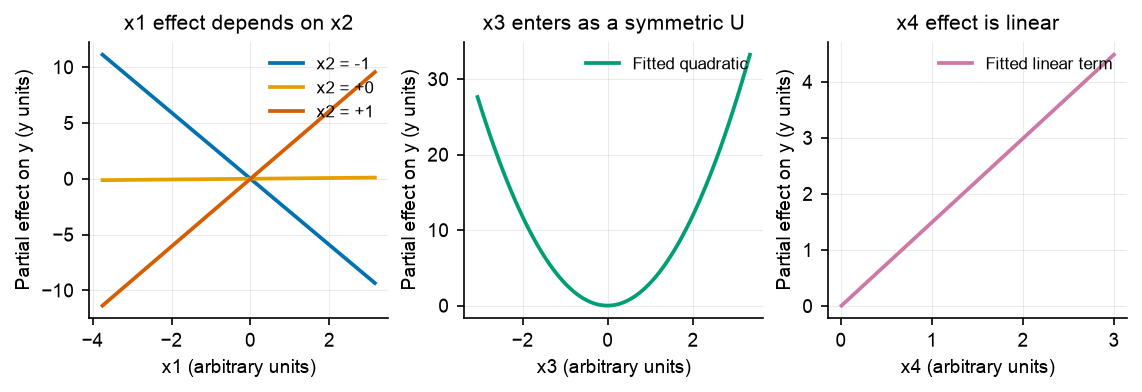

In [22]:
fig = ap.plot_fitted_effects(final, df)

## 8. Summary

The fitted model is

    y = -3.00 + 3.00 * x1 * x2 + 2.97 * x3^2 + 1.50 * x4 + e,    sd(e) = exp(-0.54 + 0.60 * x4)

with the `x1`, `x2` and `x3` main effects retained but indistinguishable from zero
(|t| < 1.1 in all three cases). R-squared is 0.91 against 0.085 for the additive model.

| Hazard | Present? | Evidence | Handling |
|---|---|---|---|
| Collinearity | No | All VIFs 1.0; predictor correlations below 0.06 | None needed |
| Pure interaction (`x1` x `x2`) | Yes | Marginal r = 0.02 and 0.08, but the product adds 0.32 to R-squared | Product term; main effects kept for marginality |
| Symmetric nonlinearity (`x3`) | Yes | Marginal r = -0.10, linear coefficient p = 0.29, quadratic t = 72 | Quadratic term |
| Heteroscedasticity (in `x4`) | Yes | Breusch-Pagan p = 4e-14; binned residual SD 0.62 to 2.65, fitted SD 0.58 at `x4` = 0 rising to 3.48 at `x4` = 3 | Multiplicative variance model, WLS |
| Non-normal errors | No | Unweighted residuals of the same mean model fail Shapiro-Wilk (p = 5.4e-7); standardised residuals pass (p = 0.95) | Explained by the variance model; no transform |
| Non-normal marginals | Not an assumption | `x4` uniform, `y` skewed | Left alone |

Two cautions carry forward. First, the predictor ranges are limited (`x1`-`x3` roughly -3 to 3,
`x4` strictly within 0 to 3), and the quadratic and product terms make extrapolation beyond
them unsafe. Second, the exponential variance model is a description of these residuals, not a
mechanism; the bootstrap intervals above are the ones to quote if that form is doubted.

Model selection here was driven by diagnostics computed on the same 500 rows that were then
used for inference, so the reported p-values for the *selected* terms are optimistic in the
usual post-selection sense. The two retained structural terms are far from the decision
boundary (|t| > 69), so this does not affect the conclusions, but it would matter for a term
near the threshold.